# 02 · Manifold — Wu et al. 2020 AML (cell-state trajectory)

Fit the cell-state manifold with scFates. **Topology is decided from the embedding, not a scalar**: the
integrated manifold is a single continuous dome (principal-axis ratio ~1.4), so we test a **principal
curve** against a **PPT tree** and let the fit adjudicate. The curve is robustly **fold-free (2 tips, 0
forks)** across `Nodes=15/20/30`; the PPT tree only manufactures **11-14 spurious branch nodes** by
overfitting a mass with no real bifurcation. This is the **non-branching** case. The root is placed at
the **Gast/pSom-high, Crest-low** tip (developmental origin; Crest is late/terminal), and pseudotime is
read as a single gastrulation->neural-crest axis. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, warnings, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Wu2020_Hematologic-2 | category: Hematologic


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = np.linalg.svd(c, full_matrices=False)
print('whole malignant manifold:', adata.shape[0], 'cells')
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f} (~1 = round mass, no elongated arms)')
print('smoothed module geography:')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

whole malignant manifold: 96875 cells
UMAP principal-axis ratio (major/minor singular value): 1.39 (~1 = round mass, no elongated arms)
smoothed module geography:
  Gast_sm vs pSom_sm: r = -0.64
  Gast_sm vs Crest_sm: r = -0.63
  pSom_sm vs Crest_sm: r = +0.09


### Topology test — curve vs PPT tree
A fold diagnostic (min graph-distant node separation / median edge length; >1 = fold-free) plus tip/fork
counts. The curve is fold-free with exactly 2 tips and 0 forks at every node budget; the PPT tree
fragments into many spurious branch nodes. -> commit a `curve` (non-branching).

In [4]:
def fold_diag(a2):
    B = np.asarray(a2.uns['graph']['B']); F = a2.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
for Nn in [100, 200]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, method='ppt', Nodes=Nn, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False, basis='umap')
    B = np.asarray(a2.uns['graph']['B']); print(f'PPT tree N={Nn}: {int((B.sum(0)==1).sum())} tips, {int((B.sum(0)>=3).sum())} branch nodes (spurious)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.97
curve N=30: 2 tips, 0 forks | self-approach 2.41
PPT tree N=100: 7 tips, 5 branch nodes (spurious)
PPT tree N=200: 12 tips, 10 branch nodes (spurious)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)


### Root from the developmental signature order
Sum smoothed module scores over cells within graph-distance 3 of each tip; root at the **Gast/pSom-high,
Crest-low** tip (origin). Fit pseudotime and confirm the axis runs origin -> Crest-high terminus, and
is not a cell-cycle artefact.

In [5]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
for m,lb_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lb_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
cyc = np.maximum(adata.obs['S_score'], adata.obs['G2M_score'])
print(f'caveat: pseudotime vs cycling score rho = {spearmanr(t, cyc)[0]:+.2f} (cell-cycle-free axis)')

tip 0: Gast=+0.0026 pSom=+0.0067 Crest=-0.0053
tip 2: Gast=+0.0029 pSom=+0.0063 Crest=-0.0042
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.048 p=1.9e-51
  pSom_sm: rho=-0.067 p=6.1e-98
  Crest_sm: rho=+0.432 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.86
Somitogenesis-high decile mean pseudotime = 0.44
Gastrulation-high decile mean pseudotime = 0.53
caveat: pseudotime vs cycling score rho = -0.11 (cell-cycle-free axis)


### Rename milestones + house orientation

In [6]:
# label the two milestones by developmental role
mil = {str(root): 'Origin (Gast/pSom)'}
other = [str(tp) for tp in tps if tp != root]
for o in other: mil[o] = 'Terminus (Crest)'
try:
    scf.tl.rename_milestones(adata, new=mil)
except Exception as e:
    print('milestone rename note:', e)
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation corr(x_lin, pseudotime) = {r:+.2f} (origin pole on left)')

house orientation corr(x_lin, pseudotime) = +0.98 (origin pole on left)


### Persist `manifold.h5ad` + `manifold.pdf` (house linear pseudotime panel)

saved manifold.h5ad + manifold.pdf


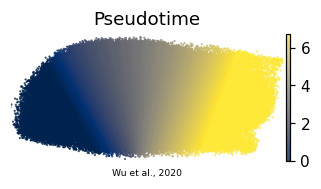

In [7]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])} if 'epg' in adata.uns and isinstance(adata.uns['epg'], dict) and 'NodePositions' in adata.uns['epg'] else adata.uns.get('epg', {})
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=8, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')